# Task 1

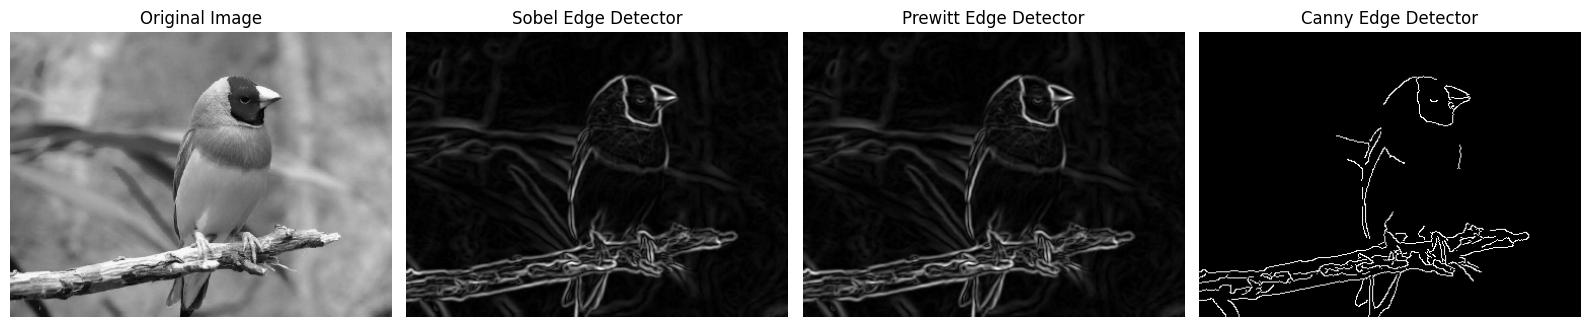

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("bird.png")
if image is None:
    raise FileNotFoundError("bird.png")
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.normalize(cv2.magnitude(sobel_x, sobel_y), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64))
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64))
prewitt = cv2.normalize(cv2.magnitude(prewitt_x, prewitt_y), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

canny = cv2.Canny(blurred, 100, 200)

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(rgb)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(sobel, cmap="gray")
ax[1].set_title("Sobel Edge Detector")
ax[1].axis("off")
ax[2].imshow(prewitt, cmap="gray")
ax[2].set_title("Prewitt Edge Detector")
ax[2].axis("off")
ax[3].imshow(canny, cmap="gray")
ax[3].set_title("Canny Edge Detector")
ax[3].axis("off")
plt.tight_layout()
plt.show()

# Task 2

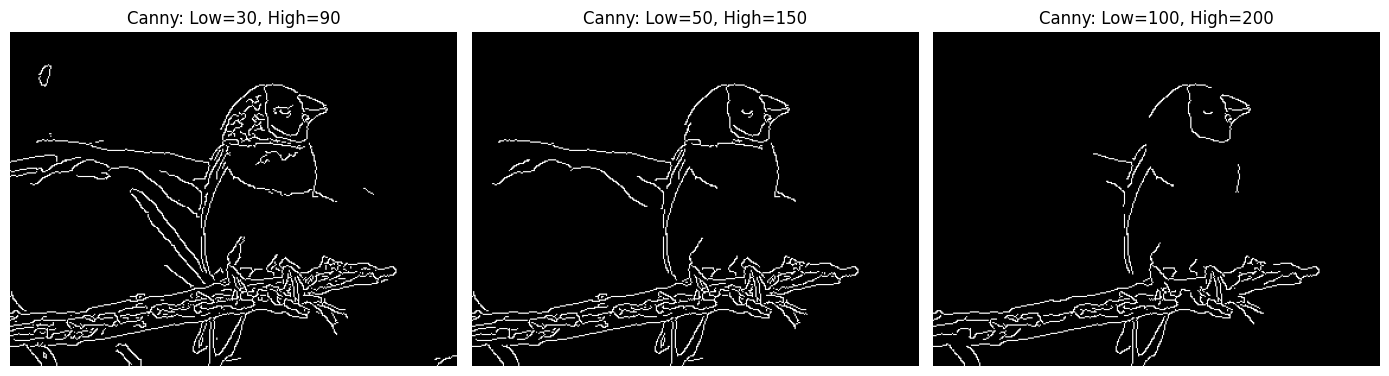

In [2]:
thresholds = [(30, 90), (50, 150), (100, 200)]
edge_maps = [cv2.Canny(blurred, low, high) for low, high in thresholds]

fig, ax = plt.subplots(1, 3, figsize=(14, 5))
for axis, edge_map, pair in zip(ax, edge_maps, thresholds):
    axis.imshow(edge_map, cmap="gray")
    axis.set_title(f"Canny: Low={pair[0]}, High={pair[1]}")
    axis.axis("off")
plt.tight_layout()
plt.show()

With thresholds 30 and 90, the detector is more sensitive and usually identifies more edges, including weaker details and some noise. Thresholds 50 and 150 provide a middle level of sensitivity. Thresholds 100 and 200 are stricter, so fewer weak edges remain while stronger boundaries are more likely to be retained. Raising the thresholds can make the result cleaner, but may remove fine details.